In [92]:
import numpy as np
import pandas as pd
import torch
import sklearn as sk
import matplotlib.pyplot as plt

from torch import nn

## Data Processing

In [93]:
path_img = '/Users/viktordyminskyi/Documents/vic/UCU/Data Science 2025 - 2027/GEN AI/CV/archive/train-images.idx3-ubyte'

def load_images(path):
    raw = open(path, 'rb').read()

    n = int.from_bytes(raw[4:8])
    row = int.from_bytes(raw[8:12])
    cols = int.from_bytes(raw[12:16])

    images = np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, row, cols)

    return images

In [97]:
path_labels = '/Users/viktordyminskyi/Documents/vic/UCU/Data Science 2025 - 2027/GEN AI/CV/archive/train-labels.idx1-ubyte'

def load_labels(path):
    raw_labels = open(path, 'rb').read()

    labels = np.frombuffer(raw_labels, dtype=np.uint8, offset=8)
    return labels

np.uint8(3)

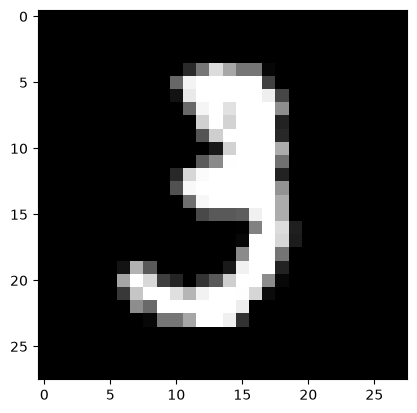

In [100]:
train_images = load_images(path_img)
train_labels = load_labels(path_labels)
test_images = load_images(path='/Users/viktordyminskyi/Documents/vic/UCU/Data Science 2025 - 2027/GEN AI/CV/archive/t10k-images.idx3-ubyte')
test_labels = load_labels(path='/Users/viktordyminskyi/Documents/vic/UCU/Data Science 2025 - 2027/GEN AI/CV/archive/t10k-labels.idx1-ubyte')

plt.imshow(train_images[10], cmap='gray')
train_labels[10]

## Model NN

In [138]:

class CouplingLayer(nn.Module):
    def __init__(self, hidden_layer_features, mask):
        super().__init__()
        self.register_buffer('mask', mask.bool())
        n = int(mask.sum())

        self.Layer_1 = nn.Linear(n, hidden_layer_features)
        self.Layer_2 = nn.Linear(hidden_layer_features, hidden_layer_features)
        self.Layer_3 = nn.Linear(hidden_layer_features, 2*n)


    def _s_t(self, x_A):
        out = self.Layer_3(torch.relu(self.Layer_2(torch.relu(self.Layer_1(x_A)))))
        s, t = out.chunk(2, dim=1)
        
        return torch.tanh(s), t


    def forward(self, X):

        X_A = X[:, self.mask]
        X_B = X [:, ~self.mask]

        s, t = self._s_t(X_A)

        X_B_changed = X_B * torch.exp(s) + t

        y = X.clone()
        y[:, ~self.mask] = X_B_changed

        log_det = s.sum(dim=1)

        return y, log_det

    def inverse(self, Y):
        Y_A = Y[:, self.mask]
        Y_B = Y[:, ~self.mask]

        s, t = self._s_t(Y_A)

        X_B = (Y_B - t) * torch.exp(-s) # same as divisison by exp(s)

        x = Y.clone()
        x[:, ~self.mask] = X_B
        
        return x

    

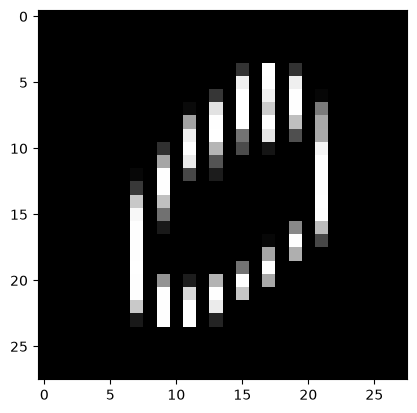

In [139]:
# print(train_images[0].shape)
mask = torch.arange(784) % 2
x_A = torch.from_numpy(train_images[1]).float().reshape(784) * mask
plt.imshow(x_A.reshape(28, 28), cmap='gray')

#### Trying ####

In [140]:
img_s = torch.randn(4, 784)
mask = torch.arange(784) % 2
first_layer_result = CouplingLayer(784, mask)
y, det = first_layer_result(img_s)
y,det

(tensor([[-1.2312,  1.3313,  1.4362,  ...,  1.9749,  1.1531, -0.4700],
         [-1.5981,  1.0295,  0.9235,  ..., -0.2092, -2.5040,  0.0194],
         [-0.3073,  0.3048,  1.7285,  ..., -1.5054, -0.1845, -1.0647],
         [ 0.0096, -0.4339,  1.1421,  ..., -0.5550,  1.5887, -0.3789]],
        grad_fn=<IndexPutBackward0>),
 tensor([-2.2492, -2.0550, -2.3228, -1.0766], grad_fn=<SumBackward1>))

In [141]:
layer = CouplingLayer(256, mask)
x = torch.randn(4, 784)
y, _ = layer(x)
x_back = layer.inverse(y)
print(x_back.shape)                              # (4, 784)
print(torch.allclose(x_back, x, atol=1e-5))      # True


torch.Size([4, 784])
True


In [142]:
class RealNVP(nn.Module):
    def __init__(self, n_layers, hidden, mask):
        super().__init__()
        layers = []
        for k in range(n_layers):
            m = mask if k % 2 == 0 else 1 - mask
            layers.append(CouplingLayer(hidden, m))
        self.layers = nn.ModuleList(layers)

    def forward(self, x):
        log_det_total = 0
        for layer in self.layers:
            x, ld = layer(x)
            log_det_total = log_det_total + ld
        return x, log_det_total

    def inverse(self, z):
        for layer in reversed(self.layers):
            z = layer.inverse(z)
        return z


## Training Part ##

In [ ]:
def prepare(images):
    x = torch.from_numpy(images).float().reshape(-1, 784)
    x = (x + torch.rand_like(x)) / 256.0
    return x

train_x = prepare(train_images)
loader = torch.utils.data.DataLoader(train_x, batch_size=128, shuffle=True)


def nll_loss(z, log_det):
    log_pz = (-0.5 * z**2 - 0.9189).sum(dim=1)
    return -(log_pz + log_det).mean()


In [144]:
device = 'mps' if torch.backends.mps.is_available() else 'cpu'
model = RealNVP(n_layers=8, hidden=512, mask=mask).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(10):
    total = 0
    for x in loader:
        x = x.to(device)
        z, log_det = model(x)
        loss = nll_loss(z, log_det)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(x)
    print(f'epoch {epoch}: loss {total / len(train_x):.1f}')


epoch 0: loss -1356.6
epoch 1: loss -1674.6
epoch 2: loss -1751.9
epoch 3: loss -1795.1
epoch 4: loss -1825.3
epoch 5: loss -1846.4
epoch 6: loss -1862.6
epoch 7: loss -1875.0
epoch 8: loss -1885.5
epoch 9: loss -1894.3


## Generation ##

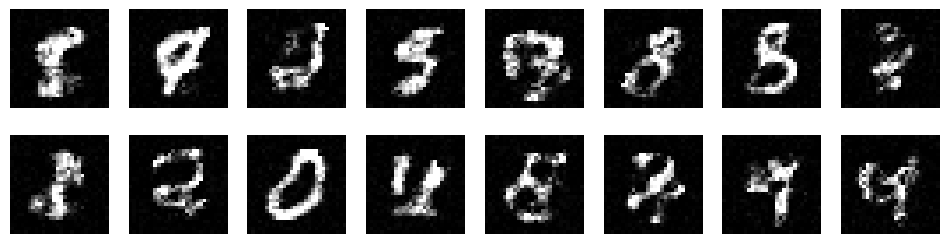

In [145]:
model.eval()
with torch.no_grad():
    z = torch.randn(16, 784, device=device)
    x = model.inverse(z).clamp(0, 1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for img, ax in zip(x, axes.flat):
    ax.imshow(img.reshape(28, 28), cmap='gray')
    ax.axis('off')
plt.show()


## Fashion MNIST ##

Same model, same training, only the data is different. The files are in the same format as MNIST, so `load_images` reads them.

In [ ]:
fashion_path = '/Users/viktordyminskyi/Documents/vic/UCU/Data Science 2025 - 2027/GEN AI/CV/fashion'

fashion_train_images = load_images(f'{fashion_path}/train-images-idx3-ubyte')
fashion_test_images = load_images(f'{fashion_path}/t10k-images-idx3-ubyte')

plt.imshow(fashion_train_images[10], cmap='gray')

In [ ]:
fashion_train_x = prepare(fashion_train_images)
fashion_loader = torch.utils.data.DataLoader(fashion_train_x, batch_size=128, shuffle=True)

In [ ]:
fashion_model = RealNVP(n_layers=8, hidden=512, mask=mask).to(device)
fashion_optimizer = torch.optim.Adam(fashion_model.parameters(), lr=1e-3)

for epoch in range(10):
    total = 0
    for x in fashion_loader:
        x = x.to(device)
        z, log_det = fashion_model(x)
        loss = nll_loss(z, log_det)

        fashion_optimizer.zero_grad()
        loss.backward()
        fashion_optimizer.step()
        total += loss.item() * len(x)
    print(f'epoch {epoch}: loss {total / len(fashion_train_x):.1f}')

In [ ]:
fashion_test_x = prepare(fashion_test_images).to(device)

fashion_model.eval()
with torch.no_grad():
    z, log_det = fashion_model(fashion_test_x)
    print(f'test loss: {nll_loss(z, log_det).item():.1f}')

### Generation (Fashion) ###

In [ ]:
fashion_model.eval()
with torch.no_grad():
    z = torch.randn(16, 784, device=device)
    x = fashion_model.inverse(z).clamp(0, 1).cpu()

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for img, ax in zip(x, axes.flat):
    ax.imshow(img.reshape(28, 28), cmap='gray')
    ax.axis('off')
plt.show()

# Part 2: Multi-Scale RealNVP #

**Problem with the Part 1 model.** It sees an image as a flat list of 784 numbers. Its coupling network is a `Linear` layer, so it does not know which pixels are neighbours: each pixel's `s` and `t` come from one big weighted sum over half of the picture. It can learn "this pixel is usually white" but has a hard time learning shapes such as a continuous stroke.

**What multi-scale changes:**
1. **Convolutional couplings.** `s` and `t` for a pixel are computed from the pixels around it (3×3 convolutions), so local shapes are easy to learn.
2. **Checkerboard mask.** A = black squares, B = white squares. Every B pixel has A neighbours on all four sides, so it is predicted from its direct neighbours.
3. **Squeeze.** Each 2×2 block of pixels becomes 4 channels: `(1, 28, 28) -> (4, 14, 14)`. After that, a 3×3 convolution covers a 6×6 area of the original image. The model first models fine details, then coarser structure.
4. **Channel mask.** After squeeze, A = first half of the channels, B = second half.
5. **Factor out.** After each scale, half of the values go straight to `z`. They already look Gaussian (fine details), so we stop spending layers on them. The remaining half goes through more layers.

```
x (1,28,28) -> 3 checkerboard couplings -> squeeze (4,14,14) -> 3 channel couplings -> half to z  (2,14,14) = 392 numbers
            (2,14,14) -> 3 checkerboard -> squeeze (8,7,7)   -> 3 channel couplings -> half to z  (4,7,7)   = 196 numbers
            (4,7,7)   -> 4 checkerboard couplings                                    -> rest to z (4,7,7)   = 196 numbers
                                                                                        total:     784 numbers
```

In [ ]:
import math

def squeeze(x):
    # (B, C, H, W) -> (B, 4C, H/2, W/2): every 2x2 block of pixels becomes 4 channels
    B, C, H, W = x.shape
    x = x.reshape(B, C, H // 2, 2, W // 2, 2)
    x = x.permute(0, 1, 3, 5, 2, 4)
    return x.reshape(B, C * 4, H // 2, W // 2)


def unsqueeze(x):
    # exact inverse of squeeze
    B, C, H, W = x.shape
    x = x.reshape(B, C // 4, 2, 2, H, W)
    x = x.permute(0, 1, 4, 2, 5, 3)
    return x.reshape(B, C // 4, H * 2, W * 2)


def checkerboard_mask(H, W):
    i = torch.arange(H).view(-1, 1)
    j = torch.arange(W).view(1, -1)
    return ((i + j) % 2).float().view(1, 1, H, W)


def channel_mask(C):
    m = torch.zeros(1, C, 1, 1)
    m[:, :C // 2] = 1
    return m


x = torch.randn(2, 1, 28, 28)
print(squeeze(x).shape, torch.equal(unsqueeze(squeeze(x)), x))
plt.imshow(checkerboard_mask(28, 28)[0, 0], cmap='gray')

### Convolutional coupling layer ###

Same idea as `CouplingLayer` from Part 1: A stays, B is changed as `x_B * exp(s) + t`, `log_det = sum(s)`.

The difference is how A and B are picked. Instead of indexing `x[:, mask]`, we keep the full image shape (convolutions need it):
- the network gets `x * mask` (B positions are zeroed, so it only sees A),
- it outputs `s` and `t` for every position, and we multiply them by `1 - mask`. On A positions `s = 0, t = 0`, so `x * exp(0) + 0 = x`: A is unchanged.

Two small tricks for stable training:
- The last convolution starts at zero, so at the start every layer is the identity (`s = 0, t = 0`).
- `s = scale * tanh(s)`: `tanh` keeps `s` in [-1, 1] like in Part 1, and the learned `scale` lets the model go beyond that if it needs to.

In [ ]:
class ConvCouplingLayer(nn.Module):
    def __init__(self, channels, hidden, mask):
        super().__init__()
        self.register_buffer('mask', mask)
        self.net = nn.Sequential(
            nn.Conv2d(channels, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, 2 * channels, 3, padding=1),
        )
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)
        self.scale = nn.Parameter(torch.ones(1, channels, 1, 1))

    def _s_t(self, x_A):
        s, t = self.net(x_A).chunk(2, dim=1)
        s = self.scale * torch.tanh(s)
        return s * (1 - self.mask), t * (1 - self.mask)

    def forward(self, x):
        s, t = self._s_t(x * self.mask)
        y = x * torch.exp(s) + t
        log_det = s.sum(dim=(1, 2, 3))
        return y, log_det

    def inverse(self, y):
        s, t = self._s_t(y * self.mask)
        return (y - t) * torch.exp(-s)


def coupling_stack(n_layers, channels, hidden, mask):
    # same as in RealNVP from Part 1: the mask flips every layer
    layers = []
    for k in range(n_layers):
        m = mask if k % 2 == 0 else 1 - mask
        layers.append(ConvCouplingLayer(channels, hidden, m))
    return nn.ModuleList(layers)


def run_forward(layers, x):
    log_det_total = 0
    for layer in layers:
        x, ld = layer(x)
        log_det_total = log_det_total + ld
    return x, log_det_total


def run_inverse(layers, z):
    for layer in reversed(layers):
        z = layer.inverse(z)
    return z

In [ ]:
class MultiScaleRealNVP(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        # scale 1: 28x28
        self.scale1_checker = coupling_stack(3, 1, hidden, checkerboard_mask(28, 28))
        self.scale1_channel = coupling_stack(3, 4, hidden, channel_mask(4))       # after squeeze: (4, 14, 14)
        # scale 2: 14x14 (half of the channels were factored out)
        self.scale2_checker = coupling_stack(3, 2, hidden, checkerboard_mask(14, 14))
        self.scale2_channel = coupling_stack(3, 8, hidden, channel_mask(8))       # after squeeze: (8, 7, 7)
        # final: 7x7
        self.final = coupling_stack(4, 4, hidden, checkerboard_mask(7, 7))

    def forward(self, x):
        x = x.reshape(-1, 1, 28, 28)

        x, ld1 = run_forward(self.scale1_checker, x)
        x = squeeze(x)
        x, ld2 = run_forward(self.scale1_channel, x)
        z1, x = x[:, :2], x[:, 2:]                  # factor out: z1 is (2, 14, 14)

        x, ld3 = run_forward(self.scale2_checker, x)
        x = squeeze(x)
        x, ld4 = run_forward(self.scale2_channel, x)
        z2, x = x[:, :4], x[:, 4:]                  # factor out: z2 is (4, 7, 7)

        z3, ld5 = run_forward(self.final, x)

        z = torch.cat([z1.flatten(1), z2.flatten(1), z3.flatten(1)], dim=1)   # 392 + 196 + 196 = 784
        return z, ld1 + ld2 + ld3 + ld4 + ld5

    def inverse(self, z):
        B = z.shape[0]
        z1 = z[:, :392].reshape(B, 2, 14, 14)
        z2 = z[:, 392:588].reshape(B, 4, 7, 7)
        z3 = z[:, 588:].reshape(B, 4, 7, 7)

        x = run_inverse(self.final, z3)

        x = torch.cat([z2, x], dim=1)
        x = run_inverse(self.scale2_channel, x)
        x = unsqueeze(x)
        x = run_inverse(self.scale2_checker, x)

        x = torch.cat([z1, x], dim=1)
        x = run_inverse(self.scale1_channel, x)
        x = unsqueeze(x)
        x = run_inverse(self.scale1_checker, x)
        return x.reshape(B, 784)

#### Checking it ####
Like for `CouplingLayer`: inverse(forward(x)) must give x back, and our `log_det` must equal the real log-determinant of the Jacobian (computed by autograd on one image). The weights are perturbed a bit first, because with the zero init every layer is the identity and the test would be trivial.

In [ ]:
check = MultiScaleRealNVP(hidden=16)
with torch.no_grad():
    for p in check.parameters():
        p += 0.01 * torch.randn_like(p)

x = torch.randn(4, 784)
z, log_det = check(x)
print('invertible:', torch.allclose(check.inverse(z), x, atol=1e-4))

J = torch.autograd.functional.jacobian(lambda v: check(v.unsqueeze(0))[0][0], x[0])
print('log_det from model:', log_det[0].item(), ' real:', torch.slogdet(J)[1].item())

### Data: train / validation / test ###

- The last 5000 training images are the **validation set** (to watch for overfitting during training); the test set is used once at the end.
- **Dequantization in every batch.** In Part 1 `prepare` added the noise once, so the model saw the same noisy image every epoch. Now we keep the pixels as 0..255 and add fresh `U(0, 1)` noise to every batch, so the model cannot memorize the noise.
- **Logit transform.** Pixels live in [0, 1] and most of them are exactly 0 (background). The flow has to map them to a Gaussian, which lives on (-inf, inf). `logit(p) = log(p / (1 - p))` stretches [0, 1] to (-inf, inf) before the flow. `ALPHA = 0.05` keeps us away from `logit(0) = -inf`. It is just one more invertible step, so its log-det is added to the flow's log-det. Otherwise the likelihood would be wrong.
- **Bits per dimension** is the standard metric for flows: `loss / (784 * ln 2)` converted to 8-bit pixels. It does not depend on the image size, so numbers can be compared to papers (RealNVP on MNIST: around 1.0-1.1 bits/dim; lower is better).

In [ ]:
def to_tensor(images):
    return torch.from_numpy(images).float().reshape(-1, 784)   # values 0..255, noise is added later

mnist_train, mnist_val = to_tensor(train_images[:55000]), to_tensor(train_images[55000:])
mnist_test = to_tensor(test_images)
fashion_train, fashion_val = to_tensor(fashion_train_images[:55000]), to_tensor(fashion_train_images[55000:])
fashion_test = to_tensor(fashion_test_images)
print(len(mnist_train), len(mnist_val), len(mnist_test))

ALPHA = 0.05

def to_logit(x):
    x = (x + torch.rand_like(x)) / 256              # dequantize
    p = ALPHA + (1 - 2 * ALPHA) * x
    y = torch.log(p) - torch.log(1 - p)
    log_det = (math.log(1 - 2 * ALPHA) - torch.log(p) - torch.log(1 - p)).sum(dim=1)
    return y, log_det


def from_logit(y):
    return ((torch.sigmoid(y) - ALPHA) / (1 - 2 * ALPHA)).clamp(0, 1)


def bits_per_dim(loss):
    # loss is the NLL of images in [0, 1]; + 784 * ln(256) turns it into the NLL of 0..255 pixels
    return (loss + 784 * math.log(256)) / (784 * math.log(2))

### Train loop with validation ###
Same loop as in Part 1, plus:
- after every epoch, the validation bits/dim (no gradients),
- a cosine learning-rate schedule (large steps first, small at the end),
- gradient clipping: a single bad batch can produce a huge gradient through `exp(s)`; clipping stops it from breaking the model.

In [ ]:
def evaluate(model, data):
    model.eval()
    total = 0
    with torch.no_grad():
        for x in data.split(1000):
            x = x.to(device)
            y, ld_logit = to_logit(x)
            z, log_det = model(y)
            total += nll_loss(z, log_det + ld_logit).item() * len(x)
    return bits_per_dim(total / len(data))


def train(model, train_data, val_data, epochs, lr=1e-3):
    loader = torch.utils.data.DataLoader(train_data, batch_size=128, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs * len(loader))
    history = {'train': [], 'val': []}

    for epoch in range(epochs):
        model.train()
        total = 0
        for x in loader:
            x = x.to(device)
            y, ld_logit = to_logit(x)
            z, log_det = model(y)
            loss = nll_loss(z, log_det + ld_logit)

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 100)
            optimizer.step()
            scheduler.step()
            total += loss.item() * len(x)

        history['train'].append(bits_per_dim(total / len(train_data)))
        history['val'].append(evaluate(model, val_data))
        print(f"epoch {epoch}: train {history['train'][-1]:.3f} bits/dim, val {history['val'][-1]:.3f} bits/dim")
    return history


def plot_history(histories, title):
    for name, h in histories.items():
        epochs = range(1, len(h['train']) + 1)
        line, = plt.plot(epochs, h['train'], label=f'{name} train')
        plt.plot(epochs, h['val'], '--', color=line.get_color(), label=f'{name} val')
    plt.xlabel('epoch')
    plt.ylabel('bits / dim')
    plt.title(title)
    plt.legend()
    plt.show()


def show_samples(model, temperature=1.0, n=32, title=''):
    model.eval()
    with torch.no_grad():
        z = torch.randn(n, 784, device=device) * temperature
        x = from_logit(model.inverse(z)).cpu()
    fig, axes = plt.subplots(n // 8, 8, figsize=(8, n // 8 + 0.4))
    for img, ax in zip(x, axes.flat):
        ax.imshow(img.reshape(28, 28), cmap='gray')
        ax.axis('off')
    fig.suptitle(title)
    plt.show()

## Multi-Scale RealNVP on MNIST Digits ##

In [ ]:
EPOCHS = 20
torch.manual_seed(0)
mnist_ms = MultiScaleRealNVP(hidden=64).to(device)
print('parameters:', sum(p.numel() for p in mnist_ms.parameters()))
mnist_history = train(mnist_ms, mnist_train, mnist_val, EPOCHS)

In [ ]:
plot_history({'multi-scale': mnist_history}, 'MNIST Digits')
mnist_test_bpd = evaluate(mnist_ms, mnist_test)
print(f'test: {mnist_test_bpd:.3f} bits/dim')

In [ ]:
show_samples(mnist_ms, temperature=1.0, title='MNIST, T = 1.0')
show_samples(mnist_ms, temperature=0.7, title='MNIST, T = 0.7')

## Multi-Scale RealNVP on Fashion MNIST ##

In [ ]:
torch.manual_seed(0)
fashion_ms = MultiScaleRealNVP(hidden=64).to(device)
fashion_history = train(fashion_ms, fashion_train, fashion_val, EPOCHS)

In [ ]:
plot_history({'multi-scale': fashion_history}, 'Fashion MNIST')
fashion_test_bpd = evaluate(fashion_ms, fashion_test)
print(f'test: {fashion_test_bpd:.3f} bits/dim')

In [ ]:
show_samples(fashion_ms, temperature=1.0, title='Fashion, T = 1.0')
show_samples(fashion_ms, temperature=0.7, title='Fashion, T = 0.7')

# Part 3: Experiments #

### 1. Architecture: MLP (Part 1) vs Multi-Scale ###
The Part 1 models were trained on images in [0, 1] without the logit step, so their NLL can be converted to bits/dim directly with the same `bits_per_dim`. The test images get the noise once, as in `prepare`.

In [ ]:
def evaluate_mlp(model, images):
    model.eval()
    with torch.no_grad():
        x = prepare(images).to(device)
        z, log_det = model(x)
        return bits_per_dim(nll_loss(z, log_det).item())

count = lambda m: sum(p.numel() for p in m.parameters())
results = pd.DataFrame({
    'parameters': [count(model), count(mnist_ms)],
    'MNIST test bits/dim': [evaluate_mlp(model, test_images), mnist_test_bpd],
    'Fashion test bits/dim': [evaluate_mlp(fashion_model, fashion_test_images), fashion_test_bpd],
}, index=['MLP RealNVP (Part 1, 10 epochs)', 'Multi-scale RealNVP (20 epochs)'])
results.round(3)

### 2. Width of the coupling network ###
Same multi-scale model on MNIST with `hidden = 32` instead of 64 (about 4 times fewer parameters).

In [ ]:
torch.manual_seed(0)
mnist_ms_small = MultiScaleRealNVP(hidden=32).to(device)
print('parameters:', count(mnist_ms_small))
mnist_history_small = train(mnist_ms_small, mnist_train, mnist_val, EPOCHS)
mnist_small_test_bpd = evaluate(mnist_ms_small, mnist_test)
print(f'test: {mnist_small_test_bpd:.3f} bits/dim (hidden=64: {mnist_test_bpd:.3f})')

In [ ]:
plot_history({'hidden=64': mnist_history, 'hidden=32': mnist_history_small}, 'MNIST: width of the coupling network')
show_samples(mnist_ms_small, temperature=0.7, n=16, title='hidden = 32, T = 0.7')

### 3. Sampling temperature ###
A sample is `inverse(z)` with `z ~ N(0, 1)`. With temperature `T` we use `z ~ N(0, T²)` instead: `z` closer to 0 means a point closer to the centre of the Gaussian, where the model puts the most typical images. This does not change the model, only which part of it we look at.

In [ ]:
for T in [1.0, 0.85, 0.7, 0.5]:
    show_samples(mnist_ms, temperature=T, n=16, title=f'MNIST, T = {T}')
for T in [1.0, 0.85, 0.7, 0.5]:
    show_samples(fashion_ms, temperature=T, n=16, title=f'Fashion, T = {T}')

# Report #

_(written after the run, see below)_